# EDA: iPSC / organoid culture images from PPTX exports

Images were extracted from two PowerPoint sources into `pptx_images/`. Duplicate and unlabeled images were already removed from the original set, so **the dataset has gaps by construction**. This notebook:

1. Builds a metadata dataframe (filepath, source pptx, group, day) from filenames.
2. Profiles image properties (format, size, brightness, sharpness).
3. Characterizes missingness, including inferring where the removals likely happened.
4. Re-checks for any duplicates that survived.

In [ ]:
# Download the dataset from the shared Google Drive folder (one-time auth prompt in Colab).
# https://drive.google.com/drive/folders/1LI8eviJsYzSQRN3-rlJU_3dWL7ppxK7k
from pathlib import Path

from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

FOLDER_ID = '1LI8eviJsYzSQRN3-rlJU_3dWL7ppxK7k'
ROOT = Path('pptx_images')
FOLDER_MIME_TYPE = 'application/vnd.google-apps.folder'

auth.authenticate_user()
drive_service = build('drive', 'v3')


def download_folder(folder_id, destination):
    # Uses the Drive API rather than gdown, which refuses folders with more than 50 files.
    destination.mkdir(parents=True, exist_ok=True)
    page_token = None
    while True:
        response = drive_service.files().list(
            q=f"'{folder_id}' in parents and trashed=false",
            fields='nextPageToken, files(id, name, mimeType)',
            pageSize=1000, pageToken=page_token,
            supportsAllDrives=True, includeItemsFromAllDrives=True,
        ).execute()
        for item in response['files']:
            target = destination / item['name']
            if item['mimeType'] == FOLDER_MIME_TYPE:
                download_folder(item['id'], target)
            elif not target.exists():
                partial = target.with_name(target.name + '.part')
                with open(partial, 'wb') as file:
                    request = drive_service.files().get_media(fileId=item['id'], supportsAllDrives=True)
                    downloader = MediaIoBaseDownload(file, request)
                    done = False
                    while not done:
                        _, done = downloader.next_chunk()
                partial.rename(target)
        page_token = response.get('nextPageToken')
        if not page_token:
            return


download_folder(FOLDER_ID, ROOT)

EXPECTED_DATA_DIRS = {'3-protocols-images', 'KOLF-022026-batch'}
actual_dirs = {child.name for child in ROOT.iterdir() if child.is_dir()}

if not EXPECTED_DATA_DIRS.issubset(actual_dirs):
    raise FileNotFoundError(f'Missing dataset folders: {EXPECTED_DATA_DIRS - actual_dirs}')

print(f'Dataset folder: {ROOT} ({sum(1 for f in ROOT.rglob("*") if f.is_file())} files)')

In [ ]:
import re, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage
import imagehash

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 80, "display.width", 160)

ROOT = Path("pptx_images")

## 1. Organize the data

Filename conventions (the only metadata available):

- **`3-protocols-images/`** → `3protocols_s{slide}_{slide title}_Day{N}.{tif|png}`.
  `group` = slide (`s006`, …); one slide holds up to ~6 consecutive days of one culture. Slide titles are truncated at ~60 characters.
- **`KOLF-022026-batch/`** → `KOLF022026_{stage}_{condition}_{timepoint}.png`.
  `group` = condition (`APP`, `NDC`, `PS1`, `PS2`). Timepoint is `D#`, or `iPSC` / `EBs` (no numeric day).

Extra parsed columns: `slide`, `cell_line`, `protocol`, `stage`.

In [ ]:
PCT_LINES = ["KOLFB2", "KOLF", "WTADB2", "WTAD", "H9B2", "H9"]  # longest first so B2 variants match before parents

def parse_3protocols(path):
    m = re.fullmatch(r"3protocols_s(\d+)_(.+)_Day(\d+)\.\w+", path.name)
    slide, title, day = int(m[1]), m[2], int(m[3])
    first = title.split("-")[0]
    cell_line = next((c for c in PCT_LINES if first.upper() == c), np.nan)
    protocol = next((p for p in ["Pasca", "Lancaster", "Cleber"] if p.lower() in title.lower()), np.nan)
    return dict(source_pptx="3protocols", group=f"s{slide:03d}", slide=slide, slide_title=title,
                cell_line=cell_line, protocol=protocol, stage=np.nan, day=day, timepoint=f"Day{day}")

def parse_kolf_batch(path):
    m = re.fullmatch(r"KOLF022026_(.+)_([A-Za-z0-9]+)_([A-Za-z0-9]+)\.\w+", path.name)
    stage, condition, tp = m[1], m[2], m[3]
    day = int(tp[1:]) if re.fullmatch(r"D\d+", tp) else np.nan
    return dict(source_pptx="KOLF022026", group=condition, slide=np.nan, slide_title=np.nan,
                cell_line="KOLF", protocol=np.nan, stage=stage, day=day, timepoint=tp)

PARSERS = {"3-protocols-images": parse_3protocols, "KOLF-022026-batch": parse_kolf_batch}

rows = []
for folder, parser in PARSERS.items():
    for path in sorted((ROOT / folder).iterdir()):
        rows.append({"filepath": str(path), **parser(path)})

df = pd.DataFrame(rows)
df[["day", "slide"]] = df[["day", "slide"]].astype("Int64")
df["ext"] = df["filepath"].str.extract(r"\.(\w+)$")[0]
print(df.shape)
df.head()

(531, 11)


,filepath,source_pptx,group,slide,slide_title,cell_line,protocol,stage,day,timepoint,ext
0,pptx_images/3-protocols-images/3protocols_s006_KOLF-Pasca-NI-with-SB-Dorso-W...,3protocols,s006,6,KOLF-Pasca-NI-with-SB-Dorso-Wnt-day-1-5,KOLF,Pasca,NaN,1,Day1,tif
1,pptx_images/3-protocols-images/3protocols_s006_KOLF-Pasca-NI-with-SB-Dorso-W...,3protocols,s006,6,KOLF-Pasca-NI-with-SB-Dorso-Wnt-day-1-5,KOLF,Pasca,NaN,2,Day2,tif
2,pptx_images/3-protocols-images/3protocols_s006_KOLF-Pasca-NI-with-SB-Dorso-W...,3protocols,s006,6,KOLF-Pasca-NI-with-SB-Dorso-Wnt-day-1-5,KOLF,Pasca,NaN,3,Day3,tif
3,pptx_images/3-protocols-images/3protocols_s006_KOLF-Pasca-NI-with-SB-Dorso-W...,3protocols,s006,6,KOLF-Pasca-NI-with-SB-Dorso-Wnt-day-1-5,KOLF,Pasca,NaN,4,Day4,tif
4,pptx_images/3-protocols-images/3protocols_s006_KOLF-Pasca-NI-with-SB-Dorso-W...,3protocols,s006,6,KOLF-Pasca-NI-with-SB-Dorso-Wnt-day-1-5,KOLF,Pasca,NaN,5,Day5,tif


Every file parsed with no exceptions (the regexes would have raised). Quick sanity check of the parsed columns:

In [ ]:
print(df.groupby("source_pptx").agg(images=("filepath", "size"), groups=("group", "nunique"),
                                    min_day=("day", "min"), max_day=("day", "max")))
print()
print(df.isna().sum().to_frame("n_missing").T)

             images  groups  min_day  max_day
source_pptx                                  
3protocols      502      95        1       46
KOLF022026       29       4        2       23

           filepath  source_pptx  group  slide  slide_title  cell_line  protocol  stage  day  timepoint  ext
n_missing         0            0      0     29           29         49        78    502    8          0    0


Notes on the `NaN`s: `slide`/`slide_title`/`protocol` don't apply to the KOLF batch; `stage` doesn't apply to 3protocols. `day` is missing for the KOLF `iPSC` and `EBs` images (pre-differentiation stages with no day number). In 3protocols, `cell_line`/`protocol` are `NaN` for slides whose titles don't follow the pattern (`Bright-45`, `Batch-3-B3-…`, `untitled`).

## 2. Overview of the dataset

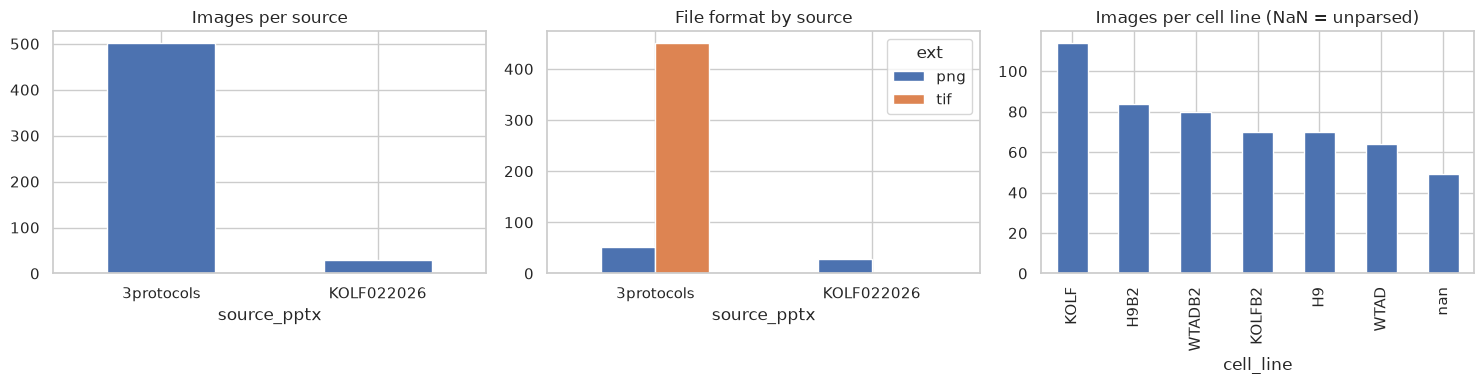

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["source_pptx"].value_counts().plot.bar(ax=axes[0], rot=0, title="Images per source")
df.groupby(["source_pptx", "ext"]).size().unstack(fill_value=0).plot.bar(ax=axes[1], rot=0, title="File format by source")
df["cell_line"].value_counts(dropna=False).plot.bar(ax=axes[2], title="Images per cell line (NaN = unparsed)")
plt.tight_layout()

3protocols is ~95% of the data and mostly TIFF; the KOLF batch is a small, all-PNG set. Among the six parsed cell lines, KOLF is the largest (~110 images) and the rest are within ~65–85 each, so cell-line imbalance is mild. ~9% of images have no parseable cell line.

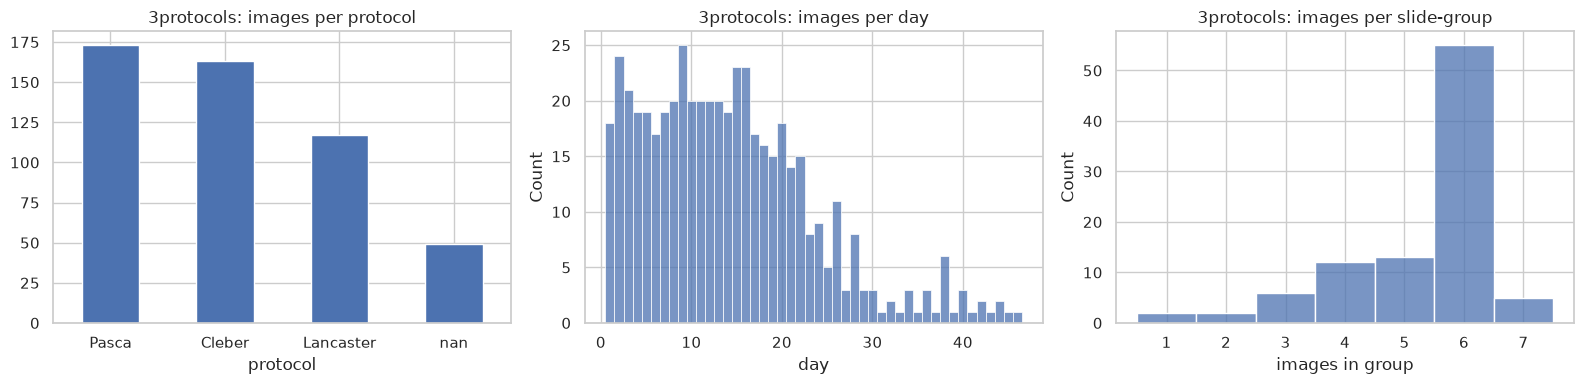

In [ ]:
p = df[df.source_pptx == "3protocols"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
p["protocol"].value_counts(dropna=False).plot.bar(ax=axes[0], rot=0, title="3protocols: images per protocol")
sns.histplot(p["day"].astype(float), bins=np.arange(0.5, 47.5), ax=axes[1]); axes[1].set_title("3protocols: images per day")
sns.histplot(p.groupby("group").size(), discrete=True, ax=axes[2]); axes[2].set_title("3protocols: images per slide-group"); axes[2].set_xlabel("images in group")
plt.tight_layout()

- Pasca (~173) and Cleber (~163) have the most images, Lancaster fewer (~117); ~49 images have no parsed protocol.
- Day coverage is front-loaded: ~15–25 images per day through day ~20, then a steady decline, and only 1–6 images per day beyond day ~30. Late-stage cultures are sparse.
- The modal slide-group has 6 images (one per day), with a long tail of smaller groups and a few of 7. Smaller groups are candidates for lost images (see §5).

## 3. Image properties

In [ ]:
def image_properties(path):
    with Image.open(path) as im:
        mode, (width, height) = im.mode, im.size
        rgba = im.convert("RGBA")
    arr = np.asarray(rgba)
    alpha_min = int(arr[..., 3].min())
    gray = np.asarray(rgba.convert("L"), dtype=np.float32)
    rgb = arr[..., :3].astype(np.float32)
    small = gray[::4, ::4]  # downsample for speed
    return dict(width=width, height=height, mode=mode, alpha_min=alpha_min,
                brightness=gray.mean(), contrast=gray.std(),
                sharpness=ndimage.laplace(small).var(),
                saturation=(rgb.max(-1) - rgb.min(-1)).mean(),
                frac_near_white=(gray > 245).mean(), frac_near_black=(gray < 10).mean())

props = pd.DataFrame([image_properties(f) for f in df["filepath"]])
df = pd.concat([df.drop(columns=props.columns, errors="ignore"), props], axis=1)
df["megapixels"] = df.width * df.height / 1e6
df["file_kb"] = [Path(f).stat().st_size / 1024 for f in df.filepath]
df["aspect"] = df.width / df.height
df.describe().T[["count", "mean", "std", "min", "max"]].round(2)

,count,mean,std,min,max
slide,502.0,68.103586,35.610014,6.0,125.0
day,523.0,13.929254,9.419998,1.0,46.0
width,531.0,1459.33145,512.282955,484.0,4032.0
height,531.0,1098.962335,386.405597,365.0,3040.0
alpha_min,531.0,255.0,0.0,255.0,255.0
brightness,531.0,93.305702,22.463539,38.434879,174.960526
contrast,531.0,72.646278,15.158379,18.458157,107.669823
sharpness,531.0,2487.924805,1159.464355,291.464661,7793.345215
saturation,531.0,3.115185,13.616636,0.009985,104.403503
frac_near_white,531.0,0.074528,0.08754,0.000888,0.464049


In [ ]:
print(df.groupby(["source_pptx", "ext", "mode"]).agg(n=("filepath", "size"),
      sizes=("width", lambda s: s.nunique()), min_w=("width", "min"), max_w=("width", "max")))
print("\nImages with any transparent pixels (alpha_min < 255):", int((df.alpha_min < 255).sum()))
print("Aspect ratio range:", df.aspect.min().round(3), "-", df.aspect.max().round(3))

                        n  sizes  min_w  max_w
source_pptx ext mode                          
3protocols  png P       8      1   1360   1360
                RGBA   43     10    484   1494
            tif RGB   451      1   1360   1360
KOLF022026  png RGBA   29      4   3282   4032

Images with any transparent pixels (alpha_min < 255): 0
Aspect ratio range: 1.326 - 1.329


**Resolution is not uniform.** All TIFFs are 1360×1024 RGB. PNGs are a mix of palettized/RGBA images at many sizes (484–1494 px wide in 3protocols, 3282–4032 px in the KOLF batch), which suggests they were extracted from slides as rescaled screenshots rather than original microscope exports. Aspect ratio is ~1.33 across the board, so resizing to a common shape is straightforward. Resolution should be treated as a potential confound: in 3protocols, PNG vs TIFF correlates with *which slides* the image came from.

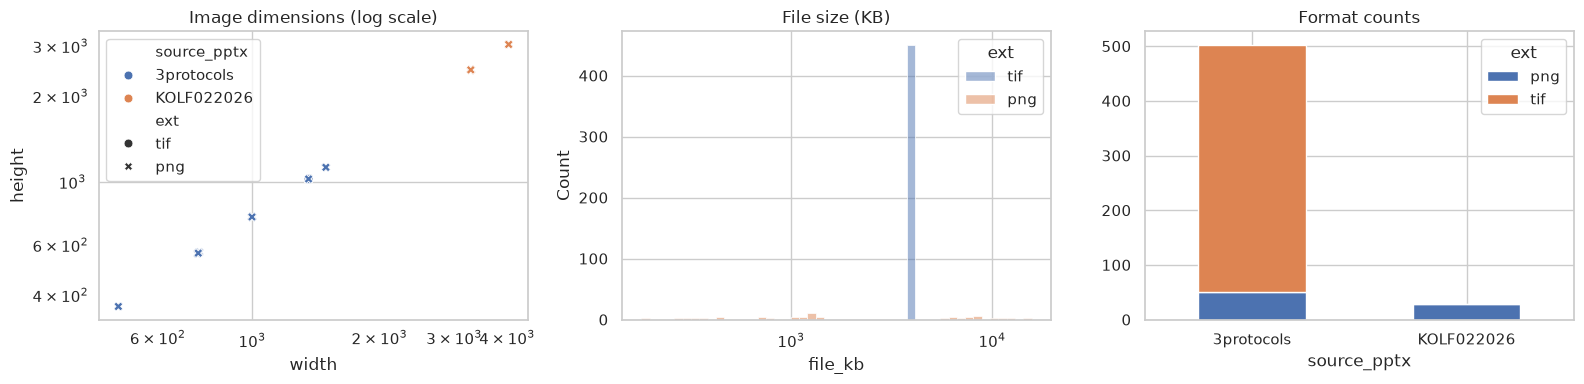

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="width", y="height", hue="source_pptx", style="ext", ax=axes[0], s=40)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_title("Image dimensions (log scale)")
sns.histplot(df, x="file_kb", hue="ext", log_scale=True, ax=axes[1]); axes[1].set_title("File size (KB)")
df.groupby(["source_pptx", "ext"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[2], rot=0, title="Format counts")
plt.tight_layout()

Dimensions form a few tight clusters (the dominant 1360×1024 TIFF cluster, a small set of downscaled PNGs, and the large KOLF batch PNGs). File sizes differ by orders of magnitude, mostly because of format and resolution rather than content.

### Intensity, contrast and sharpness

,brightness,contrast,sharpness,saturation,frac_near_white,frac_near_black
count,531.00,531.00,531.00,531.00,531.00,531.00
mean,93.31,72.65,2487.92,3.12,0.07,0.01
std,22.46,15.16,1159.46,13.62,0.09,0.06
min,38.43,18.46,291.46,0.01,0.00,0.00
25%,77.98,62.93,1695.89,0.02,0.01,0.00
50%,89.80,74.61,2295.45,0.02,0.04,0.00
75%,105.87,82.84,3116.11,0.02,0.12,0.00
max,174.96,107.67,7793.35,104.40,0.46,0.44


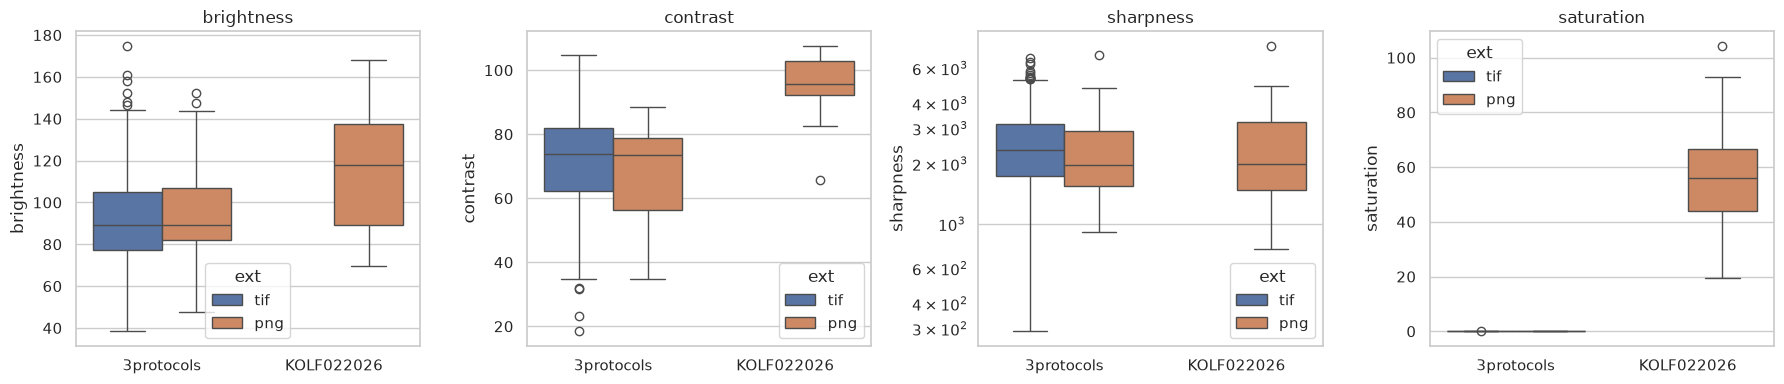

In [ ]:
metrics = ["brightness", "contrast", "sharpness", "saturation"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, metrics):
    sns.boxplot(data=df, x="source_pptx", y=m, hue="ext", ax=ax)
    ax.set_title(m); ax.set_xlabel("")
    if m == "sharpness": ax.set_yscale("log")
plt.tight_layout()
df[metrics + ["frac_near_white", "frac_near_black"]].describe().round(2)

**The two sources are different imaging modalities.** 3protocols images are effectively grayscale (saturation ≈ 0.02) while the KOLF batch images are colored (orange/brown) with higher brightness and contrast. Within 3protocols, TIFF and PNG distributions overlap closely, so format itself isn't a strong intensity confound. Sharpness (Laplacian variance) is similar across groups. Any model or comparison should treat the source as a major covariate.

In [ ]:
outliers = df.assign(z=(df.brightness - df.brightness.mean()) / df.brightness.std())
outliers = outliers.loc[outliers.z.abs() > 2.5, ["filepath", "brightness", "contrast", "sharpness", "z"]].sort_values("z")
print(f"{len(outliers)} brightness outliers (|z| > 2.5), all on the bright side: min z = {outliers.z.min():.2f}")
outliers.assign(filepath=outliers.filepath.str.replace("pptx_images/", "")).head(12)

9 brightness outliers (|z| > 2.5), all on the bright side: min z = 2.62


,filepath,brightness,contrast,sharpness,z
217,3-protocols-images/3protocols_s058_WTADB2-Pasca-Neuro-maturation-EGF-and-FGF...,152.084213,75.356537,5233.151855,2.616618
16,3-protocols-images/3protocols_s008_KOLF-Pasca-Neuro-maturation-EGF-and-FGF-d...,152.163895,81.475113,1921.415039,2.620166
514,KOLF-022026-batch/KOLF022026_EB-NI_PS1_D6.png,152.788666,104.401749,1223.998535,2.647978
505,KOLF-022026-batch/KOLF022026_EB-NI_APP_EBs.png,153.233139,103.415184,754.218994,2.667765
337,3-protocols-images/3protocols_s090_H9-Pasca-day-22-onwards-NM-factors_Day40.tif,158.086563,91.440445,970.273743,2.883822
219,3-protocols-images/3protocols_s058_WTADB2-Pasca-Neuro-maturation-EGF-and-FGF...,161.014908,83.466339,3925.197754,3.014183
517,KOLF-022026-batch/KOLF022026_EB-NI_PS2_D2.png,162.456085,87.800430,1938.265991,3.078339
503,KOLF-022026-batch/KOLF022026_EB-NI_APP_D4.png,168.109283,93.812912,2295.448730,3.330000
240,3-protocols-images/3protocols_s066_WTAD-Lancaster-Differentiation-w-CHIR-w-H...,174.960526,77.817589,5019.183594,3.634994


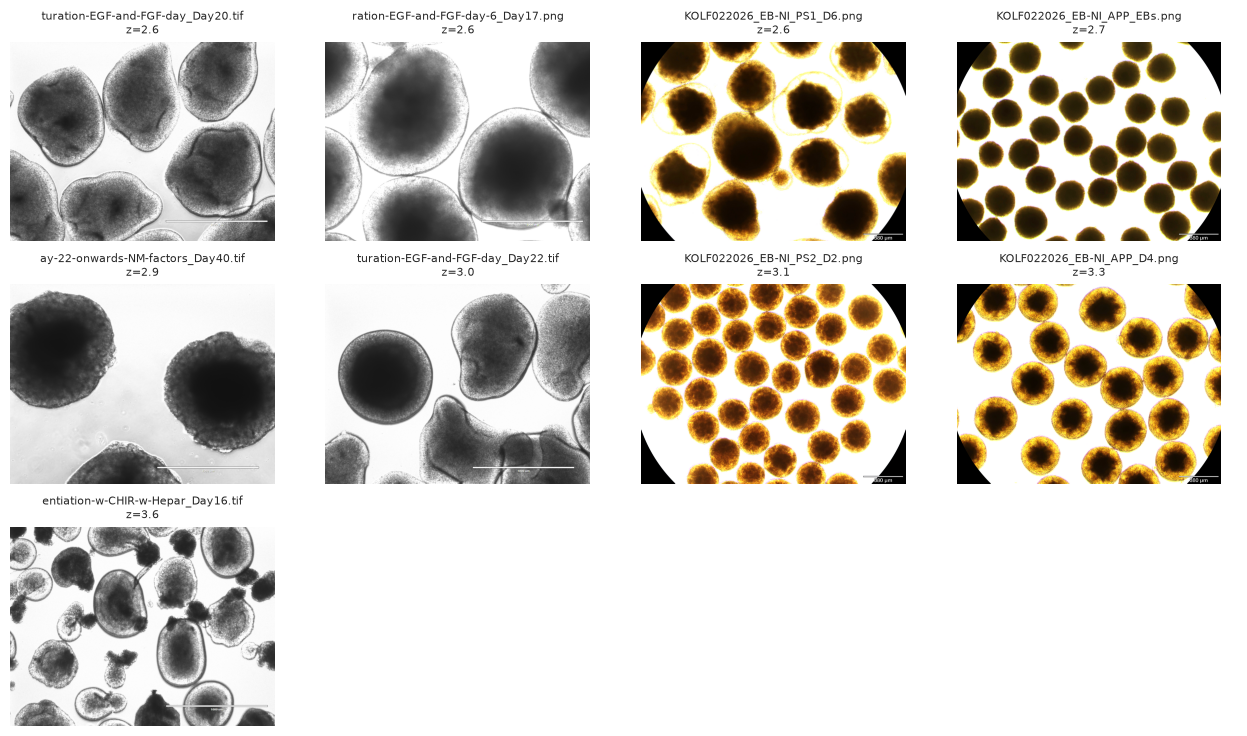

In [ ]:
def show_grid(paths, titles, ncols=4, size=3.2):
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 0.78), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, p, t in zip(axes.ravel(), paths, titles):
        with Image.open(p) as im: ax.imshow(im.convert("RGB"))
        ax.set_title(t, fontsize=8)
    plt.tight_layout()

show_grid(outliers.filepath, [f"{Path(p).name[-34:]}\nz={z:.1f}" for p, z in zip(outliers.filepath, outliers.z)])

All nine brightness outliers, dimmest to brightest. There are no dark outliers. Four of the nine are KOLF-batch images, which are bright because of their white background (the colored, circular-masked field is a different imaging setup); the 3protocols outliers are grayscale images with large white background regions, i.e. sparse fields rather than defects.

## 4. Visual look at the data

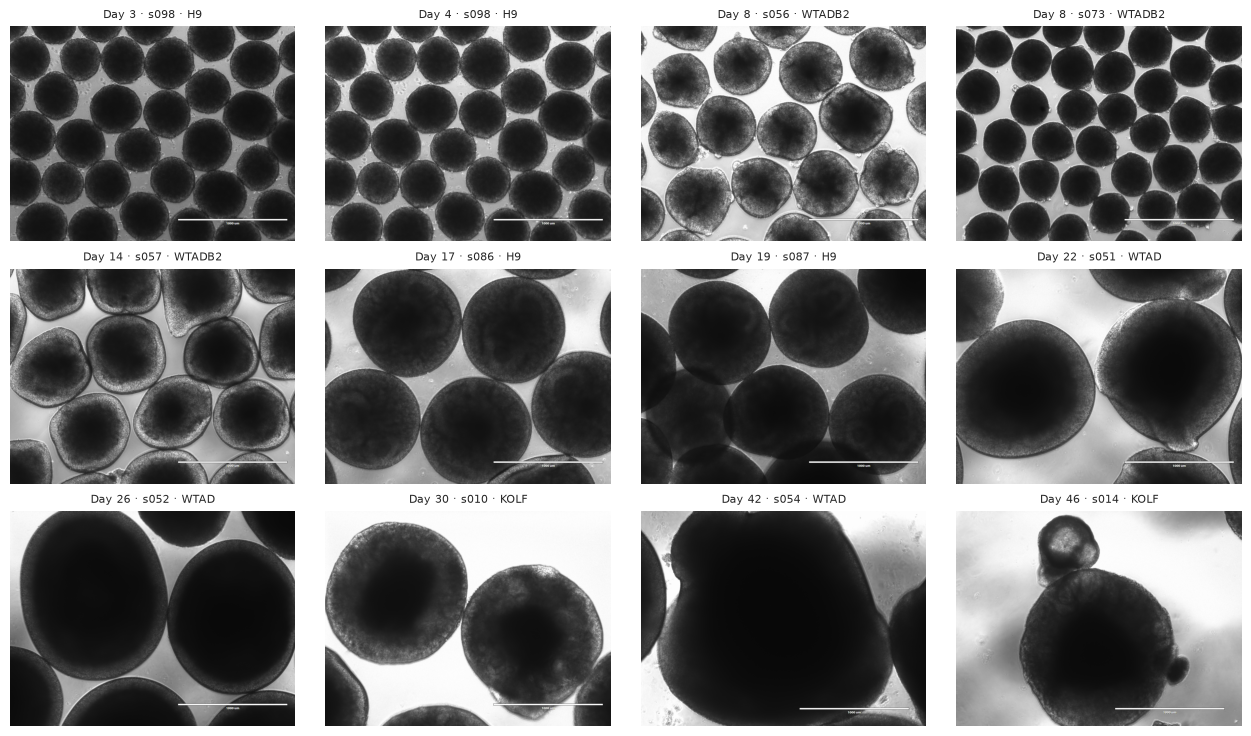

In [ ]:
rng = np.random.default_rng(0)
sample = (df[df.source_pptx == "3protocols"].dropna(subset=["day"])
          .assign(day_bin=lambda d: pd.cut(d.day.astype(int), [0, 6, 12, 18, 24, 30, 46],
                                           labels=["1-6", "7-12", "13-18", "19-24", "25-30", "31-46"]))
          .groupby("day_bin", observed=True).sample(2, random_state=0).sort_values("day"))
show_grid(sample.filepath, [f"Day {d} · {g} · {c}" for d, g, c in zip(sample.day, sample.group, sample.cell_line)], ncols=4)

Two random 3protocols examples per day range (sampled with a fixed seed). Early images show many small, round aggregates; later images show fewer, much larger and darker structures that fill the field. Every image carries a scale bar in the lower right.

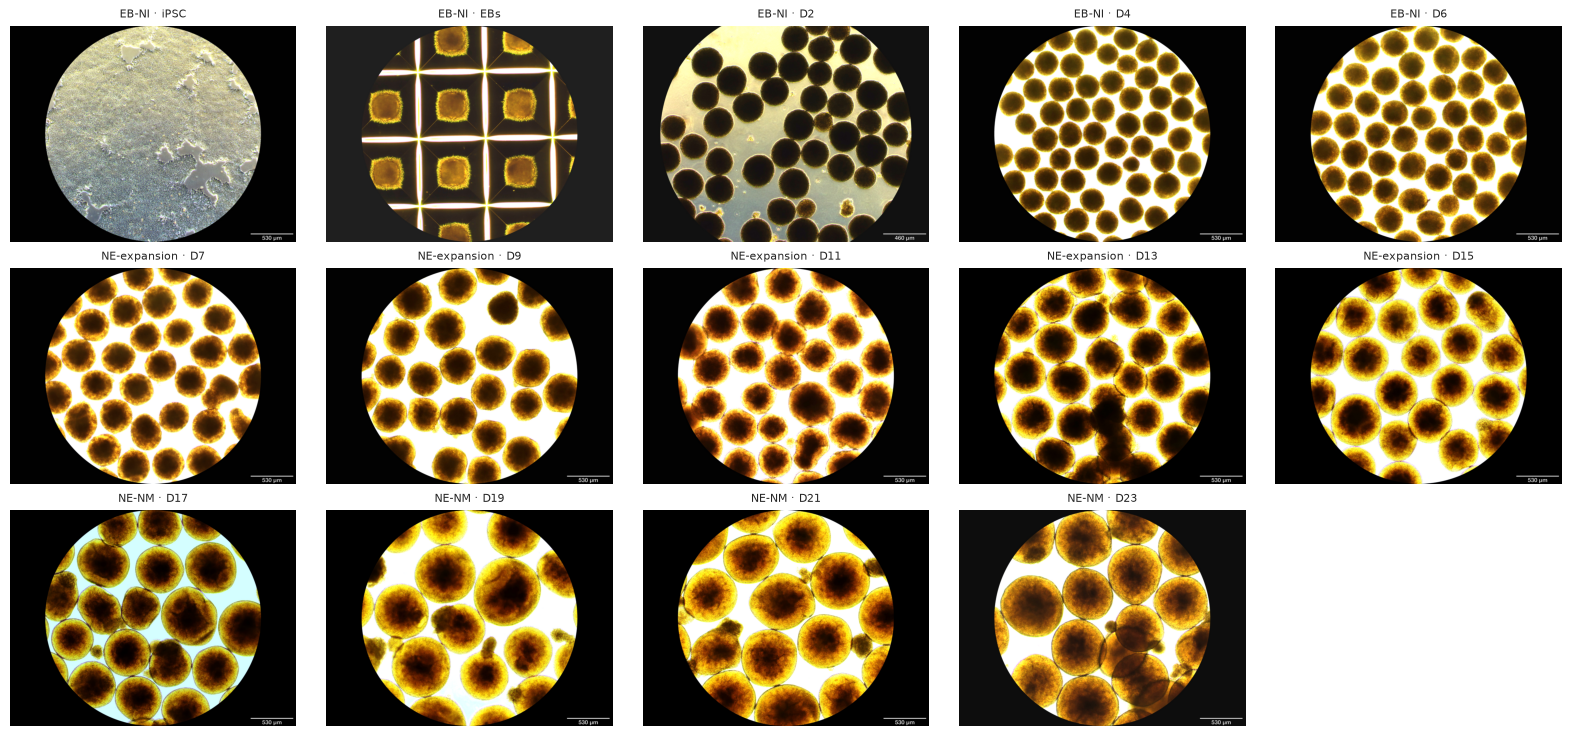

In [ ]:
kolf = df[df.source_pptx == "KOLF022026"].copy()
order = ["iPSC", "EBs", "D2", "D4", "D6", "D7", "D9", "D11", "D13", "D15", "D17", "D19", "D21", "D23"]
kolf["tp_order"] = kolf.timepoint.map({t: i for i, t in enumerate(order)})
one = kolf[kolf.group == "NDC"].sort_values("tp_order")
show_grid(one.filepath, [f"{s} · {t}" for s, t in zip(one.stage, one.timepoint)], ncols=5)

One full time series from the KOLF batch (condition `NDC`, the only condition continued past day 6): iPSC → EBs → neural induction → neuroepithelial expansion → neural maturation.

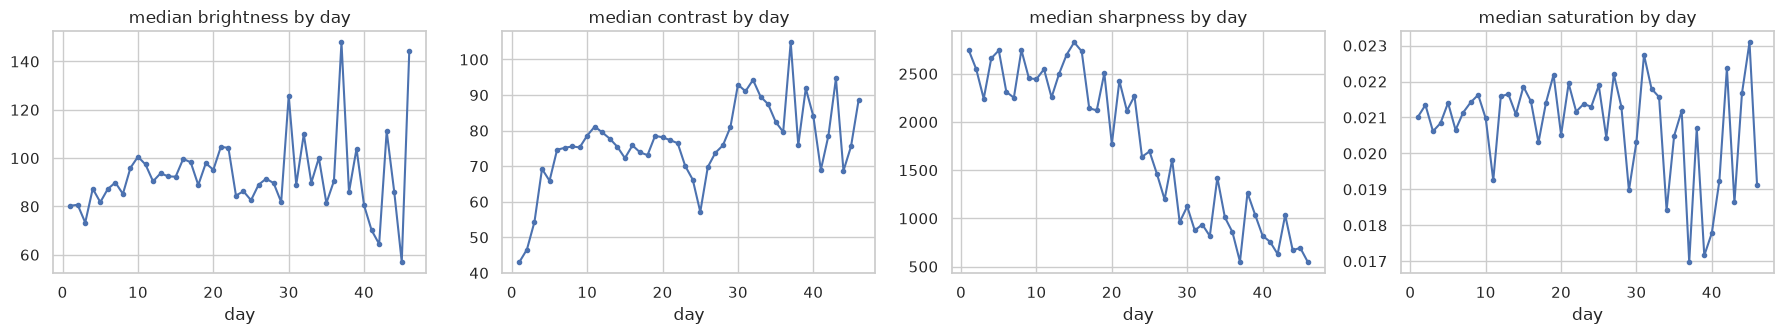

In [ ]:
daily = df[df.source_pptx == "3protocols"].groupby("day")[["brightness", "contrast", "sharpness", "saturation"]].median()
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, daily.columns):
    ax.plot(daily.index, daily[col], marker="o", ms=3); ax.set_title(f"median {col} by day"); ax.set_xlabel("day")
plt.tight_layout()

Median image statistics versus culture day (3protocols). Contrast rises and sharpness falls with day, consistent with larger, denser aggregates. Beyond day ~30 the lines get jagged because each median is based on only 1–6 images, and late days come from just a few lineages, so don't over-read the late trend.

## 5. Missingness

Duplicates and unlabeled images were removed before this dataset was handed over, so there is no ground-truth list of what's missing. We can only **infer** gaps from structure: (a) slide numbers that skip, (b) slide-groups with fewer than the usual 6 days, (c) day gaps inside a culture lineage, and (d) incomplete condition × timepoint grids in the KOLF batch.

### 5a. Metadata completeness

In [ ]:
missing_pct = df[["day", "cell_line", "protocol", "stage", "slide"]].isna().groupby(df.source_pptx).mean().mul(100).round(1)
missing_pct

,day,cell_line,protocol,stage,slide
source_pptx,,,,,
3protocols,0.0,9.8,9.8,100.0,0.0
KOLF022026,27.6,0.0,100.0,0.0,100.0


Missing values are structural (see §1); no file failed to parse. In 3protocols, ~10% of images have no parsed `cell_line`/`protocol`, all from slides with non-standard titles (listed next).

In [ ]:
p = df[df.source_pptx == "3protocols"]
print("3protocols slides with unparsed cell_line:")
p[p.cell_line.isna()].groupby(["group", "slide_title"]).size().rename("images")

3protocols slides with unparsed cell_line:


group  slide_title          
s033   Bright-45                3
       Bright-55                3
s047   untitled                 1
s083   untitled                 1
s120   Batch-3-B3-0-XAV         7
s121   Batch-3-B3-1-4000-XAV    7
s122   Batch-3-B3-1-2000-XAV    6
s123   Batch-4-B4-0-XAV         7
s124   Batch-4-B4-1-4000-XAV    7
s125   Batch-4-B4-1-2000-XAV    7
Name: images, dtype: int64

### 5b. Skipped slide numbers (3protocols)

slides 6-125: 95 present, 25 absent
absent slide numbers: [12, 18, 19, 20, 21, 22, 23, 24, 25, 36, 46, 53, 59, 60, 61, 62, 70, 82, 89, 95, 96, 97, 105, 118, 119]
contiguous absent ranges: [(12, 12), (18, 25), (36, 36), (46, 46), (53, 53), (59, 62), (70, 70), (82, 82), (89, 89), (95, 97), (105, 105), (118, 119)]


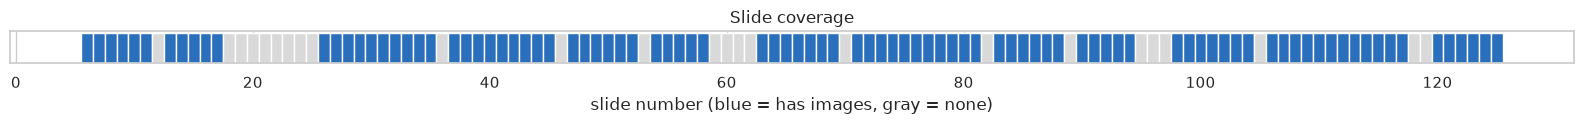

In [ ]:
present = set(p.slide.astype(int))
all_slides = range(min(present), max(present) + 1)
absent = [s for s in all_slides if s not in present]
print(f"slides {min(present)}-{max(present)}: {len(present)} present, {len(absent)} absent")
print("absent slide numbers:", absent)

runs, start = [], None
for s in all_slides:
    if s in present:
        if start is not None: runs.append((start, s - 1)); start = None
    elif start is None: start = s
print("contiguous absent ranges:", runs)

fig, ax = plt.subplots(figsize=(16, 1.4))
ax.bar(list(all_slides), [1] * len(all_slides), color=["#2a6fbb" if s in present else "#d9d9d9" for s in all_slides], width=1)
ax.set_yticks([]); ax.set_xlabel("slide number (blue = has images, gray = none)"); ax.set_title("Slide coverage")
plt.tight_layout()

25 of the 120 slide numbers between 6 and 125 are entirely absent, including an 8-slide run (18–25) and a 4-slide run (59–62). The first slide with images is 6. Likely causes: title/protocol slides with no images (expected), slides whose images were all duplicates, or slides whose images were all unlabeled. **We can't distinguish these from filenames alone**, so some ranges may be legitimate non-image slides rather than data loss.

### 5c. Incomplete slide-groups

In [ ]:
group_sizes = p.groupby("group").agg(n=("day", "size"), titles=("slide_title", "nunique"), slide_title=("slide_title", "first"),
                                      first_day=("day", "min"), last_day=("day", "max")).reset_index()
group_sizes["span"] = group_sizes.last_day - group_sizes.first_day + 1
group_sizes["missing_days_inside"] = group_sizes.span - group_sizes.n
print("Group size distribution:\n", group_sizes.n.value_counts().sort_index().to_string())
print("\nGroups with <6 images:", (group_sizes.n < 6).sum(), "of", len(group_sizes))
print("Groups with a gap in the middle of their day range:", (group_sizes.missing_days_inside > 0).sum())
group_sizes[(group_sizes.n < 6)].sort_values("n").head(25)

Group size distribution:
 n
1     2
2     2
3     6
4    12
5    13
6    55
7     5

Groups with <6 images: 35 of 95
Groups with a gap in the middle of their day range: 16


,group,n,titles,slide_title,first_day,last_day,span,missing_days_inside
30,s047,1,1,untitled,1,1,1,0
59,s083,1,1,untitled,1,1,1,0
58,s081,2,1,WTADB2-Cleber-PNI-M3-day-22-28-M2-day-28-onwa,25,26,2,0
53,s076,2,1,WTADB2-Cleber-M3-day-22-28-M2-day-28-onwards,25,26,2,0
48,s071,3,1,WTAD-Cleber,1,3,3,0
13,s028,3,1,KOLF-Lancaster-NI-day-6-12-w-o-Heparin-Failed,7,12,6,3
69,s094,3,1,H9B2-Pasca-NMEF-day-7-21-day-22-onwards-NM-fa,19,21,3,0
60,s084,3,1,H9-Pasca-NI-with-SB-Dorso-Wnt-day-1-5,2,5,4,1
88,s117,3,1,H9B2-cleber-PNI,19,21,3,0
84,s113,3,1,H9B2-cleber,19,21,3,0


`titles > 1` marks slides that hold two sub-series (e.g. `s009`, `s033`), which can legitimately be 3+3. A group with <6 images and a *contiguous* day range (`missing_days_inside == 0`) is either a short series or lost images at the ends; one with `missing_days_inside > 0` lost an interior image (or the day was never imaged).

### 5d. Day coverage per culture lineage

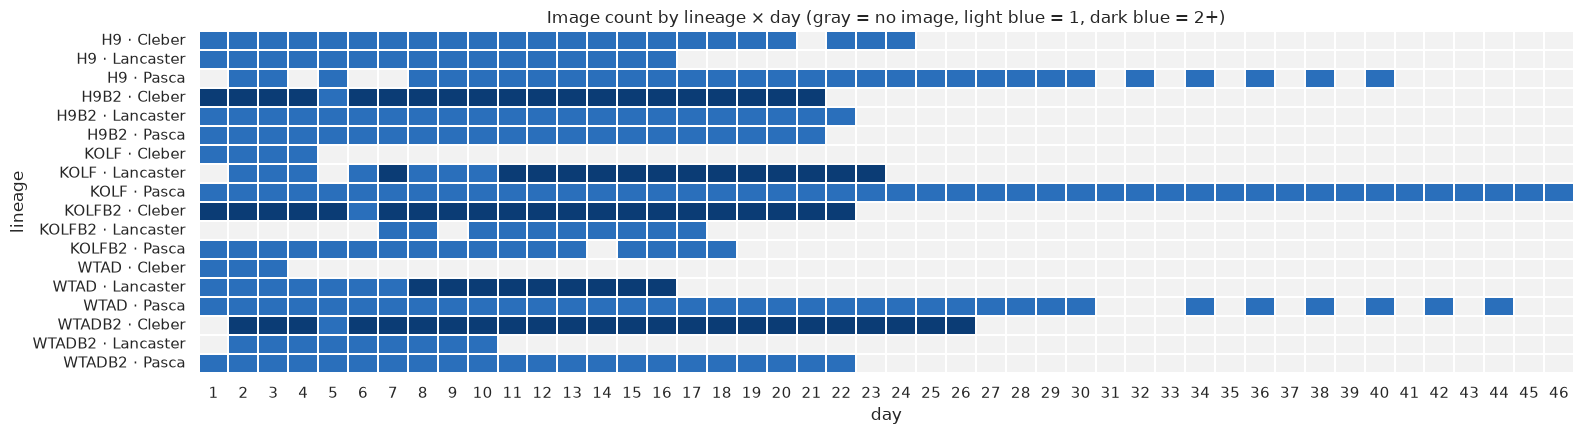

In [ ]:
lineage = p.dropna(subset=["cell_line", "protocol"]).assign(lineage=lambda d: d.cell_line + " · " + d.protocol)
coverage = lineage.assign(present=1).pivot_table(index="lineage", columns="day", values="present", aggfunc="sum").reindex(columns=range(1, 47))
coverage = coverage.fillna(0)
fig, ax = plt.subplots(figsize=(16, 4.5))
sns.heatmap(coverage, cmap=["#f2f2f2", "#2a6fbb", "#0b3c75"], vmin=0, vmax=2, cbar=False, linewidths=0.3, linecolor="white", ax=ax)
ax.set_title("Image count by lineage × day (gray = no image, light blue = 1, dark blue = 2+)")
plt.tight_layout()

Rows are cell line × protocol lineages (images with no parsed protocol are excluded); columns are culture days. Gray cells inside a lineage's active range are days with no image — never imaged or removed. Most gaps are in the 3 long Pasca lineages: `H9 · Pasca` and `WTAD · Pasca` are imaged on alternate days after day ~30, plus a few isolated early gaps (e.g. H9·Pasca days 1, 4, 6–7). Dark blue (2+ images on a day) means more than one slide maps to the same cell line and protocol. That could be replicates or protocol variants merged by this grouping (e.g. `PNI`, ±heparin), so don't read it as replicates without checking.

In [ ]:
spans = lineage.groupby("lineage").day.agg(["min", "max", "nunique"]).assign(
    span=lambda d: d["max"] - d["min"] + 1, missing_days=lambda d: d.span - d["nunique"])
spans.sort_values("missing_days", ascending=False)

,min,max,nunique,span,missing_days
lineage,,,,,
WTAD · Pasca,1,44,36,44,8
H9 · Pasca,2,40,31,39,8
KOLFB2 · Pasca,1,18,17,18,1
H9 · Cleber,1,24,23,24,1
KOLFB2 · Lancaster,7,17,10,11,1
KOLF · Lancaster,2,23,21,22,1
H9 · Lancaster,1,16,16,16,0
H9B2 · Pasca,1,21,21,21,0
H9B2 · Lancaster,1,22,22,22,0


### 5e. KOLF batch: condition × timepoint grid

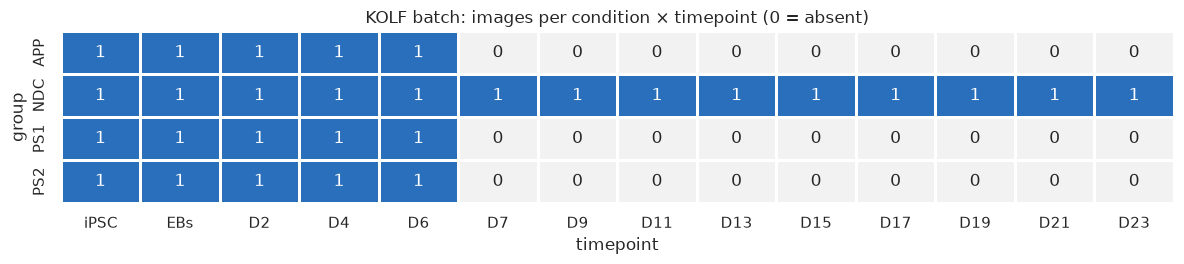

In [ ]:
grid = kolf.assign(present=1).pivot_table(index="group", columns="timepoint", values="present", aggfunc="sum").reindex(columns=order).dropna(axis=1, how="all")
grid = grid.fillna(0)
fig, ax = plt.subplots(figsize=(12, 2.8))
sns.heatmap(grid, cmap=["#f2f2f2", "#2a6fbb"], cbar=False, linewidths=1, linecolor="white", annot=True, fmt=".0f", ax=ax)
ax.set_title("KOLF batch: images per condition × timepoint (0 = absent)")
plt.tight_layout()

The grid is deliberately sparse: all four conditions (APP, NDC, PS1, PS2) have iPSC/EBs/D2/D4/D6, but only `NDC` has D7–D23 (it is the only condition continued into NE expansion and NE-NM). NDC is imaged every 2 days from D7, so no interior gap is evident. Here the missingness looks **experimental by design**, though that can't be verified from filenames.

### 5f. Is missingness related to anything observable?

In [ ]:
p_flags = p.merge(group_sizes[["group", "n"]].rename(columns={"n": "group_n"}), on="group")
p_flags["incomplete_group"] = p_flags.group_n < 6
print(p_flags.groupby("ext").incomplete_group.mean().round(2).rename("share in incomplete group"))
print()
print(p_flags.groupby("cell_line", dropna=False).incomplete_group.mean().round(2).rename("share in incomplete group, by cell line"))

ext
png    0.02
tif     0.3
Name: share in incomplete group, dtype: Float64

cell_line
H9        0.31
H9B2      0.21
KOLF      0.29
KOLFB2     0.4
WTAD      0.25
WTADB2    0.32
NaN       0.04
Name: share in incomplete group, by cell line, dtype: Float64


TIFF images are far more often in short slides (~30%) than PNGs (~2%), though the PNG slides are few, so this is weak evidence. Across cell lines the share ranges ~20–40% (KOLFB2 highest, H9B2 lowest) — no single line is wholly intact or wholly depleted. Removal doesn't look strongly line-specific, but this is a coarse check on ~95 slides.

## 6. Remaining duplicates (sanity check on the earlier de-duplication)

In [ ]:
df["md5"] = [hashlib.md5(Path(f).read_bytes()).hexdigest() for f in df.filepath]
exact = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("Exact byte-duplicates remaining:", len(exact))

def phash_of(path):
    with Image.open(path) as im: return imagehash.phash(im.convert("L"))
df["phash"] = [phash_of(f) for f in df.filepath]

Exact byte-duplicates remaining: 0


In [ ]:
hashes = df["phash"].tolist()
dist = np.array([[a - b for b in hashes] for a in hashes])
np.fill_diagonal(dist, 64)
i, j = np.where(np.triu(dist <= 6))
near = pd.DataFrame({"a": df.filepath.iloc[i].str.replace("pptx_images/", "").values,
                     "b": df.filepath.iloc[j].str.replace("pptx_images/", "").values,
                     "hamming": dist[i, j]}).sort_values("hamming")
print(f"Near-duplicate pairs (pHash Hamming <= 6): {len(near)}")
near.head(15)

Near-duplicate pairs (pHash Hamming <= 6): 1


,a,b,hamming
0,3-protocols-images/3protocols_s098_H9-Lancaster_Day3.tif,3-protocols-images/3protocols_s098_H9-Lancaster_Day4.tif,0


No byte-identical duplicates remain. One perceptual near-duplicate pair does: `s098_H9-Lancaster` **Day3 vs Day4** (pHash distance 0). Both TIFFs show what looks like the same field of aggregates, so Day 4 may be a mis-labeled copy of Day 3 (or vice versa). The pixel difference below quantifies this; confirm with the owner before dropping either.

mean abs pixel diff (0-255 scale): 18.0; same-field correlation: 0.986


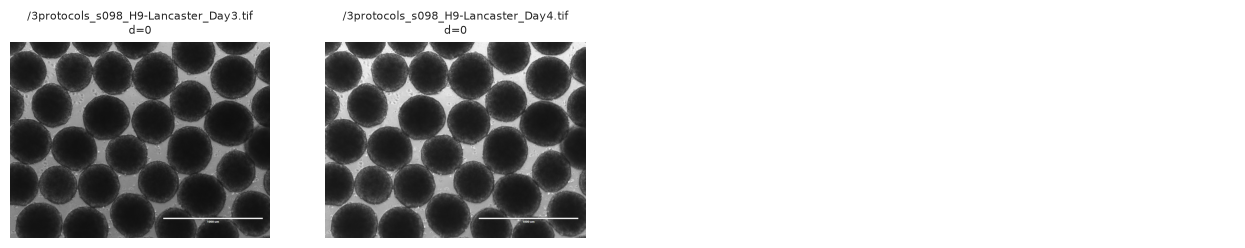

In [ ]:
a, b = [np.asarray(Image.open("pptx_images/" + near.iloc[0][k]).convert("L"), dtype=float) for k in "ab"]
print(f"mean abs pixel diff (0-255 scale): {np.abs(a - b).mean():.1f}; same-field correlation: {np.corrcoef(a.ravel(), b.ravel())[0, 1]:.3f}")
if len(near):
    top = near.head(1)
    paths, titles = [], []
    for _, r in top.iterrows():
        for side in "ab":
            paths.append("pptx_images/" + r[side]); titles.append(f"{r[side][-38:]}\nd={r.hamming}")
    show_grid(paths, titles, ncols=4)

## 7. Summary and caveats

- **Size / structure:** 531 images (502 from 3protocols across 95 slides, 29 from the KOLF batch). All filenames parse cleanly.
- **Heterogeneity:** TIFFs are all 1360×1024; PNGs vary widely in resolution. The bigger shift is modality: 3protocols is grayscale, the KOLF batch is colored with higher brightness/contrast. Treat source as a covariate, and resize/normalize before pooling.
- **Imbalance:** days 1–~20 are well covered; days 30+ have only 1–6 images each and come from a few lineages. Cell lines and protocols are only mildly imbalanced.
- **Missingness:** large runs of slide numbers are absent and some slide-groups are short or have interior day gaps. This is inferred, not confirmed — the removed images can't be identified from what's here. The KOLF batch is sparse by experimental design.
- **Duplicates:** no byte-identical files remain, but `s098` H9-Lancaster Day3/Day4 look like the same image and should be checked.
- **For modeling:** split by `group`/slide (and ideally by lineage) rather than randomly by image, since neighboring days in a slide are near-duplicates of each other and would leak across a random split.